# Image as Data: Pixel & Metadata Inspector

Notebook edukasi untuk menunjukkan bahwa gambar digital direpresentasikan sebagai angka (piksel), sekaligus memeriksa metadata teknis, EXIF, GPS, dan indikator data tambahan dalam file.

**Cara mulai:** ubah `IMAGE_PATH` di bagian konfigurasi ke lokasi gambar Anda, lalu jalankan sel dari atas ke bawah. Notebook tidak mengubah file asli; demonstrasi perubahan piksel dilakukan pada salinan array di memori.

> **Privasi:** metadata EXIF/GPS dapat mengungkap waktu atau lokasi pengambilan gambar. Periksa laporan sebelum membagikannya ke publik.

## Analisis Gambar: Piksel, Metadata, dan Lokasi

In [57]:
import hashlib
import os
from datetime import datetime

import numpy as np
from PIL import ExifTags, Image
from IPython.display import display
import matplotlib.pyplot as plt

#path gambar
IMAGE_PATH = 'Gambar.jpeg'

**1. Tampilkan gambar**

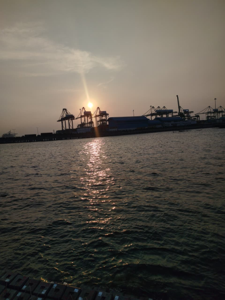

Ukuran gambar: 0.09 MB


In [58]:
import os
from PIL import Image
from IPython.display import display

img = Image.open(IMAGE_PATH)

# Perkecil gambar agar maksimal 600 x 300 piksel
img.thumbnail((600, 300))

display(img)

# Mendapatkan ukuran file asli menggunakan os.path.getsize
file_size_mb = os.path.getsize(IMAGE_PATH) / (1024 * 1024)
print(f"Ukuran gambar: {file_size_mb:.2f} MB")

## 2. Fungsi bantu dan informasi file

In [59]:
stat = os.stat(IMAGE_PATH)
with open(IMAGE_PATH, 'rb') as f:
    data = f.read()

magic = data[:8].hex(' ')

print(f'Nama file   : {os.path.basename(IMAGE_PATH)}')
print(f'Ukuran file : {stat.st_size:,} byte')
print(f'Format      : {img.format}')
print(f'Mode warna  : {img.mode}')
print(f'Resolusi    : {img.width} x {img.height}')
print(f'Dibuat (OS) : {datetime.fromtimestamp(stat.st_ctime)}')
print(f'Diubah (OS) : {datetime.fromtimestamp(stat.st_mtime)}')
print(f'MD5         : {hashlib.md5(data).hexdigest()}')
print(f'SHA-256     : {hashlib.sha256(data).hexdigest()}')
print(f'Magic bytes : {magic}')

Nama file   : Gambar.jpeg
Ukuran file : 96,234 byte
Format      : JPEG
Mode warna  : RGB
Resolusi    : 225 x 300
Dibuat (OS) : 2026-10-21 22:39:58.048653
Diubah (OS) : 2026-10-21 22:39:58.048653
MD5         : a4646044bbdfe4176785eec396618eb7
SHA-256     : 016192940240d48ba4f5eb582a429871595a207231cc998e019341ea937a648f
Magic bytes : ff d8 ff e0 00 10 4a 46


## 3. Ekstraksi EXIF, GPS, dan metadata tambahan

In [60]:
# Mengubah gambar menjadi array angka
array_gambar = np.array(img)

# Menampilkan bentuk dan dimensi array
print("Bentuk array       :", array_gambar.shape)
print("Tinggi gambar      :", array_gambar.shape[0], "pixel")
print("Lebar gambar       :", array_gambar.shape[1], "pixel")
print("Jumlah kanal warna :", array_gambar.shape[2])

# Menghitung jumlah seluruh pixel
jumlah_pixel = array_gambar.shape[0] * array_gambar.shape[1]
print("Jumlah pixel       :", f"{jumlah_pixel:,}".replace(",", "."))

# Mengetahui tipe data setiap nilai pixel
print("Tipe data pixel    :", array_gambar.dtype)

# Mengetahui kedalaman bit setiap kanal warna
kedalaman_bit = array_gambar.dtype.itemsize * 8
print("Kedalaman bit      :", kedalaman_bit, "bit per kanal")

# Menghitung jumlah bit untuk satu pixel RGB
bit_per_pixel = kedalaman_bit * array_gambar.shape[2]
print("Bit per pixel RGB  :", bit_per_pixel, "bit")

Bentuk array       : (300, 225, 3)
Tinggi gambar      : 300 pixel
Lebar gambar       : 225 pixel
Jumlah kanal warna : 3
Jumlah pixel       : 67.500
Tipe data pixel    : uint8
Kedalaman bit      : 8 bit per kanal
Bit per pixel RGB  : 24 bit


In [61]:
#MELIHAT NILAI PIXEL DALAM BENTUK ANGKA

pixel = array_gambar[0:3, 0:3]

print("Nilai pixel pada bagian 3 × 3 pertama:")
print(pixel)

Nilai pixel pada bagian 3 × 3 pertama:
[[[120 112  93]
  [120 112  93]
  [121 113  94]]

 [[120 112  93]
  [120 112  93]
  [121 113  94]]

 [[121 113  94]
  [121 113  94]
  [121 113  94]]]


In [62]:
arr = np.array(img.convert('RGB'))

print(f'Tipe hasil konversi : {type(arr)}')
print(f'Tipe data elemen    : {arr.dtype} (bilangan bulat 0-255)')
print(f'Bentuk array        : {arr.shape} (tinggi, lebar, channel)')
print(f'Total piksel        : {arr.shape[0] * arr.shape[1]:,}')
print(f'Total angka         : {arr.size:,}')
print(f'Min / Max           : {arr.min()} / {arr.max()}')
print(f'Rata-rata           : {arr.mean():.2f}')
print()
print('Channel merah, 5x5 piksel pojok kiri atas:')
print(arr[:5, :5, 0])
print()
r, g, b = arr[0, 0]
print(f'Piksel (0,0): R={r}, G={g}, B={b}')

Tipe hasil konversi : <class 'numpy.ndarray'>
Tipe data elemen    : uint8 (bilangan bulat 0-255)
Bentuk array        : (300, 225, 3) (tinggi, lebar, channel)
Total piksel        : 67,500
Total angka         : 202,500
Min / Max           : 4 / 255
Rata-rata           : 84.67

Channel merah, 5x5 piksel pojok kiri atas:
[[120 120 121 121 120]
 [120 120 121 121 120]
 [121 121 121 121 121]
 [122 122 122 122 121]
 [123 123 123 123 122]]

Piksel (0,0): R=120, G=112, B=93


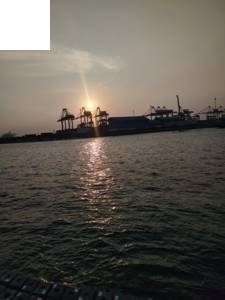

Ukuran gambar: 0.01 MB


In [63]:
from IPython.display import display
import io

modified = arr.copy()
modified[:50, :50] = 255

# Konversi array ke gambar
img_modified = Image.fromarray(modified)

# Kompres gambar menjadi JPEG
buffer = io.BytesIO()
img_modified.convert("RGB").save(
    buffer, format="JPEG", quality=70, optimize=True
)

# Tampilkan gambar hasil kompresi
buffer.seek(0)
display(Image.open(buffer))

# Cek ukuran file
print(f"Ukuran gambar: {buffer.getbuffer().nbytes / (1024 * 1024):.2f} MB")

## 4. Array NumPy, statistik RGB, histogram, dan warna dominan

Gambar RGB berbentuk array dengan dimensi `(tinggi, lebar, 3)`. Setiap piksel memuat tiga nilai intensitas warna, biasanya dari 0 sampai 255. Gambar grayscale/berpalet dikonversi ke RGB agar analisis channel konsisten.

In [64]:
#MELIHAT NILAI PIXEL DALAM BENTUK ANGKA

pixel = array_gambar[0:3, 0:3]

print("Nilai pixel pada bagian 3 × 3 pertama:")
print(pixel)

Nilai pixel pada bagian 3 × 3 pertama:
[[[120 112  93]
  [120 112  93]
  [121 113  94]]

 [[120 112  93]
  [120 112  93]
  [121 113  94]]

 [[121 113  94]
  [121 113  94]
  [121 113  94]]]


## 5. Jalankan analisis satu gambar

In [65]:
from pathlib import Path

def analyze_image(path, include_reverse_geocode=False):
    path = Path(path)
    file_info = get_file_info(path)
    exif_info = extract_exif(path)
    extra_info = detect_extra_metadata(path)
    rgb = load_rgb_array(path)
    stats, histograms = channel_statistics(rgb)
    colors = dominant_colors(path)

    geocoded_address = reverse_geocode_coordinates(
        exif_info.get("gps_latitude"),
        exif_info.get("gps_longitude"),
        enabled=include_reverse_geocode,
    )
    exif_info["gps_reverse_geocoded_address"] = geocoded_address

    report = {
        "generated_at": datetime.now().astimezone().isoformat(timespec="seconds"),
        "file": file_info,
        "exif": exif_info,
        "color_statistics": stats,
        "histograms": histograms,
        "dominant_colors": colors,
        "extra_metadata_indicators": extra_info,
        "notes": [
            "MD5 disertakan untuk identifikasi/checksum, bukan untuk keamanan kriptografis.",
            "Tidak adanya EXIF/GPS bukan bukti bahwa sebuah gambar tidak pernah memiliki metadata.",
            "Indikator data setelah penanda akhir hanya diuji untuk JPEG, PNG, dan WebP; hasil bukan bukti niat atau malware.",
            "Warna dominan merupakan perkiraan dari palet warna pada sampel gambar.",
        ],
    }
    return report, rgb

image_path_obj = Path(IMAGE_PATH)
if image_path_obj.is_file():
    report, image_array = analyze_image(
        image_path_obj,
        include_reverse_geocode=ENABLE_REVERSE_GEOCODING,
    )
    print("Analisis selesai:", report["file"]["file_name"])
    print("Format / resolusi:", report["file"]["format"], "/", report["file"]["resolution"])
    print("Ukuran:", report["file"]["size_mb"], "MB")
    print("MD5:", report["file"]["md5"])
    print("SHA-256:", report["file"]["sha256"])
else:
    report, image_array = None, None
    print(f"File belum ditemukan: {image_path_obj.resolve()}\nUbah IMAGE_PATH di sel konfigurasi, lalu jalankan kembali sel ini dan sel sesudahnya.")

Analisis selesai: Gambar.jpeg
Format / resolusi: JPEG / 960 x 1280
Ukuran: 0.0918 MB
MD5: a4646044bbdfe4176785eec396618eb7
SHA-256: 016192940240d48ba4f5eb582a429871595a207231cc998e019341ea937a648f


## 6. Bukti bahwa gambar adalah kumpulan angka

Sel ini menampilkan bentuk array, contoh nilai RGB, lalu mengubah satu area kecil menjadi merah **pada salinan array**. Perhatikan bahwa gambar hasil berubah karena angka pikselnya berubah. File asli tidak ditimpa.

Bentuk array (tinggi, lebar, channel): (1280, 960, 3)
Tipe data: uint8
Rentang nilai: 0 sampai 255
Contoh nilai RGB di pojok kiri atas (5 x 5 piksel):
 [[[120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]]

 [[120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]]

 [[120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]]

 [[120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]]

 [[120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]
  [120 112  93]]]


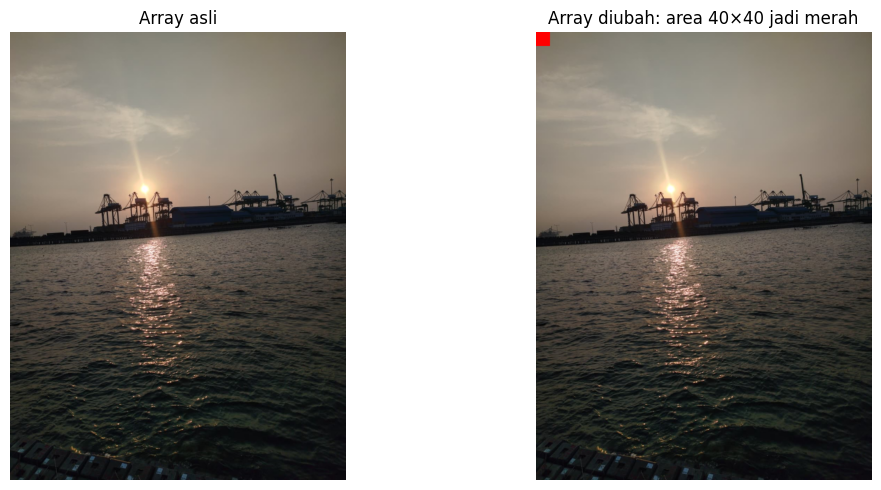

Nilai piksel (0,0) sebelum: [120, 112, 93]
Nilai piksel (0,0) sesudah: [255, 0, 0]


In [66]:
if image_array is not None:
    print("Bentuk array (tinggi, lebar, channel):", image_array.shape)
    print("Tipe data:", image_array.dtype)
    print("Rentang nilai:", int(image_array.min()), "sampai", int(image_array.max()))
    print("Contoh nilai RGB di pojok kiri atas (5 x 5 piksel):\n", image_array[:5, :5, :])

    # Salinan array; jangan mengubah image_array atau file asli.
    modified_array = image_array.copy()
    height, width, _ = modified_array.shape
    patch_h = max(1, min(40, height // 8 or 1))
    patch_w = max(1, min(40, width // 8 or 1))
    before_pixel = modified_array[0, 0].tolist()
    modified_array[:patch_h, :patch_w] = [255, 0, 0]
    after_pixel = modified_array[0, 0].tolist()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image_array)
    axes[0].set_title("Array asli")
    axes[1].imshow(modified_array)
    axes[1].set_title(f"Array diubah: area {patch_w}×{patch_h} jadi merah")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("Nilai piksel (0,0) sebelum:", before_pixel)
    print("Nilai piksel (0,0) sesudah:", after_pixel)
else:
    print("Belum ada gambar untuk didemonstrasikan. Atur IMAGE_PATH terlebih dahulu.")

## 7. Statistik channel, histogram, dan warna dominan

Statistik per channel:


,min,max,mean,median,std,p25,p75
R,0.0,255.0,91.1478,88.0,59.9884,31.0,146.0
G,0.0,255.0,85.5214,78.0,53.7089,34.0,137.0
B,0.0,255.0,76.9726,69.0,47.7737,31.0,124.0


Perkiraan warna dominan:


,hex,rgb,sampled_pixel_count,sampled_percent
0,#999082,"[153, 144, 130]",45132,16.72
1,#8A7F70,"[138, 127, 112]",36315,13.45
2,#474038,"[71, 64, 56]",35512,13.15
3,#171A19,"[23, 26, 25]",34369,12.73
4,#0C0F10,"[12, 15, 16]",33766,12.51
5,#292B26,"[41, 43, 38]",33395,12.37
6,#B2A594,"[178, 165, 148]",26128,9.68
7,#6B6055,"[107, 96, 85]",25383,9.40


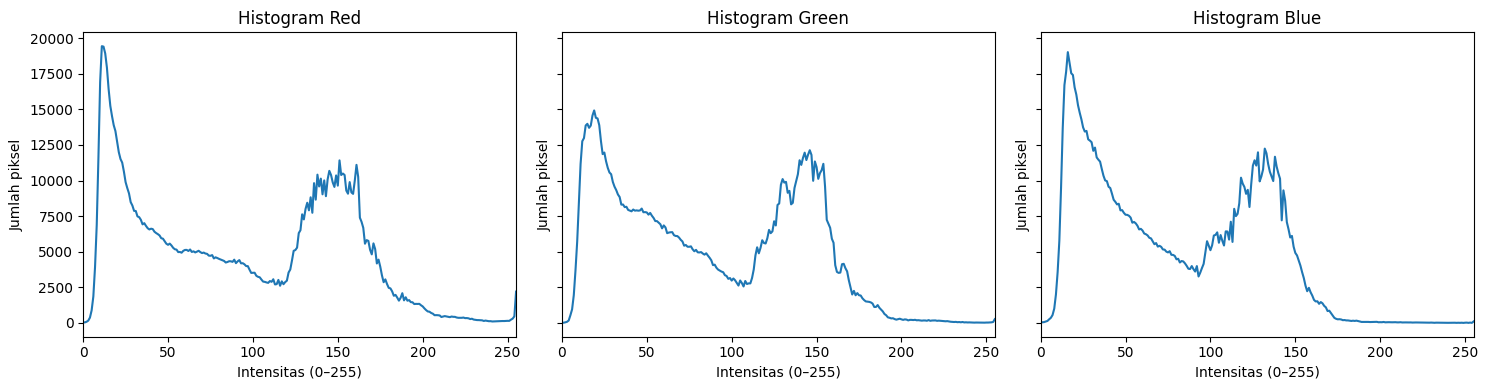

In [67]:
if report is not None:
    print("Statistik per channel:")
    display(pd.DataFrame(report["color_statistics"]).T)

    dominant_df = pd.DataFrame(report["dominant_colors"])
    print("Perkiraan warna dominan:")
    display(dominant_df)

    plot_rgb_histograms(image_array)
else:
    print("Analisis belum tersedia.")

## 8. EXIF, GPS, dan indikator metadata tambahan

In [73]:
if report is not None:
    exif = report["exif"]
    summary_keys = [
        "camera_make", "camera_model", "datetime_original", "datetime_digitized",
        "datetime_in_image", "iso", "exposure_time", "f_number", "exposure_program",
        "focal_length", "flash", "white_balance", "lens_model", "software",
        "orientation", "gps_latitude", "gps_longitude", "gps_altitude_m",
        "gps_date_stamp", "gps_timestamp_utc", "gps_map_link", "gps_reverse_geocoded_address"
    ]
    display(pd.DataFrame({"Field": key, "Value": exif.get(key)} for key in summary_keys))

    print("Indikator metadata tambahan:")
    display(pd.Series(report["extra_metadata_indicators"], name="Value").to_frame())

    if exif.get("gps_map_link"):
        print("Google Maps:", exif["gps_map_link"])
    else:
        print("Koordinat GPS tidak ditemukan dalam EXIF.")
else:
    print("Analisis belum tersedia.")

,Field,Value
0,camera_make,None
1,camera_model,None
2,datetime_original,None
3,datetime_digitized,None
4,datetime_in_image,None
5,iso,None
6,exposure_time,None
7,f_number,None
8,exposure_program,None
9,focal_length,None


Indikator metadata tambahan:


,Value
icc_profile_present,False
icc_profile_bytes,0
xmp_present,False
xmp_marker_present_in_raw_bytes,False
software_metadata_present,False
extra_info_keys,"[jfif, jfif_density, jfif_unit, jfif_version, ..."
trailing_data_check,diperiksa berdasarkan marker JPEG EOI (FFD9)
trailing_data_bytes,0
trailing_data_hex_preview,


Koordinat GPS tidak ditemukan dalam EXIF.


## 9. Simpan laporan JSON

In [71]:
import json
from pathlib import Path

# Definisikan OUTPUT_DIR jika belum ada
OUTPUT_DIR = Path("output")

def save_json_report(report_data, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as handle:
        json.dump(report_data, handle, ensure_ascii=False, indent=2, default=str)
    return output_path

if report is not None:
    # Menggunakan Path(IMAGE_PATH).stem agar aman meskipun IMAGE_PATH berupa string
    json_path = OUTPUT_DIR / f"{Path(IMAGE_PATH).stem}_report.json"
    saved_json = save_json_report(report, json_path)
    print("Laporan JSON disimpan ke:", saved_json.resolve())
else:
    print("Tidak ada laporan untuk disimpan.")

Laporan JSON disimpan ke: /content/output/Gambar_report.json


## 10. Analisis satu folder dan ekspor CSV

CSV merangkum kolom yang praktis untuk pencarian dan penyaringan. Untuk setiap gambar yang tidak dapat dibaca, notebook tetap mencatat nama file serta pesan error sehingga proses folder tidak berhenti.

In [72]:
def analyze_folder(folder_path, output_csv=None, recursive=False):
    folder_path = Path(folder_path)
    if not folder_path.is_dir():
        raise NotADirectoryError(f"Folder tidak ditemukan: {folder_path.resolve()}")

    iterator = folder_path.rglob("*") if recursive else folder_path.iterdir()
    paths = sorted(
        path for path in iterator
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    rows = []
    for path in paths:
        try:
            # Reverse geocoding sengaja tidak dilakukan untuk batch agar tidak memicu
            # banyak permintaan jaringan atau mengirim banyak koordinat ke layanan pihak ketiga.
            report_data, _ = analyze_image(path, include_reverse_geocode=False)
            file_data = report_data["file"]
            exif_data = report_data["exif"]
            extra_data = report_data["extra_metadata_indicators"]
            rows.append({
                "file_name": file_data.get("file_name"),
                "file_path": file_data.get("file_path"),
                "format": file_data.get("format"),
                "width": file_data.get("width"),
                "height": file_data.get("height"),
                "resolution": file_data.get("resolution"),
                "size_bytes": file_data.get("size_bytes"),
                "size_mb": file_data.get("size_mb"),
                "filesystem_modified_at": file_data.get("filesystem_modified_at"),
                "md5": file_data.get("md5"),
                "sha256": file_data.get("sha256"),
                "camera_make": exif_data.get("camera_make"),
                "camera_model": exif_data.get("camera_model"),
                "datetime_original": exif_data.get("datetime_original"),
                "iso": exif_data.get("iso"),
                "exposure_time": exif_data.get("exposure_time"),
                "f_number": exif_data.get("f_number"),
                "focal_length": exif_data.get("focal_length"),
                "gps_latitude": exif_data.get("gps_latitude"),
                "gps_longitude": exif_data.get("gps_longitude"),
                "gps_map_link": exif_data.get("gps_map_link"),
                "icc_profile_present": extra_data.get("icc_profile_present"),
                "xmp_present": extra_data.get("xmp_present"),
                "software_metadata_present": extra_data.get("software_metadata_present"),
                "trailing_data_bytes": extra_data.get("trailing_data_bytes"),
                "error": None,
            })
        except Exception as exc:
            rows.append({
                "file_name": path.name,
                "file_path": str(path.resolve()),
                "error": f"{type(exc).__name__}: {exc}",
            })

    df = pd.DataFrame(rows)
    if output_csv is None:
        output_csv = OUTPUT_DIR / f"{folder_path.name or 'folder'}_analysis.csv"
    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_csv, index=False, encoding="utf-8-sig")
    print(f"Selesai: {len(paths)} file ditemukan; hasil CSV: {output_csv.resolve()}")
    return df, output_csv


# Ubah FOLDER_PATH ke folder berisi gambar. Jalankan sel ini saat siap.
FOLDER_PATH = Path("gambar")
if FOLDER_PATH.is_dir():
    folder_df, csv_path = analyze_folder(
        FOLDER_PATH,
        recursive=ANALYZE_SUBFOLDERS,
    )
    display(folder_df.head(10))
else:
    print(f"Folder contoh belum ada: {FOLDER_PATH.resolve()}\nUbah FOLDER_PATH ke folder gambar Anda saat ingin membuat CSV.")

Folder contoh belum ada: /content/gambar
Ubah FOLDER_PATH ke folder gambar Anda saat ingin membuat CSV.


## 11. Cara membaca hasil dan batasan

- **Hash**: MD5/SHA-256 dihitung dari byte file mentah. Perubahan satu byte umumnya mengubah hash. MD5 disediakan untuk kebutuhan identifikasi lama; utamakan SHA-256 untuk checksum.
- **Magic bytes**: signature awal file membantu mengenali format, tetapi pemeriksaan header saja bukan validasi keamanan lengkap.
- **EXIF/GPS**: hanya tersedia bila memang disimpan dan tidak dihapus oleh aplikasi pengolah/unggah. Tanggal EXIF bisa salah atau berbeda dari tanggal sistem berkas.
- **Data tambahan di akhir file**: pengecekan sederhana untuk JPEG, PNG, dan WebP. Data trailing tidak otomatis berarti berbahaya; beberapa file/alat dapat menyimpan data tambahan secara sah.
- **Reverse geocoding**: nonaktif secara default. Bila diaktifkan, koordinat dikirim ke layanan Nominatim melalui geopy; patuhi kebijakan layanan dan pertimbangkan privasi.
- **Warna dominan**: hasil perkiraan berbasis kuantisasi, bukan klasifikasi semantik objek dalam foto.